# Análise Exploratória — Copas do Mundo FIFA (1930–2022)

**Disciplina:** Python para Data Science — Prof. Victor Lattari
**Grupo:** (Bruno Spinelli e Cauã Guerreiro)

## 1. Contexto do dataset

**Fonte:** Fjelstul World Cup Database — https://github.com/jfjelstul/worldcup
**Arquivo utilizado:** matches.csv
https://raw.githubusercontent.com/jfjelstul/worldcup/master/data-csv/matches.csv

O conjunto reúne informações sobre as Copas do Mundo FIFA masculinas e femininas.
O arquivo matches.csv cobre 30 torneios: 22 Copas masculinas (1930 a 2022) e
8 Copas femininas (1991 a 2019). A Copa feminina de 2023 não consta no arquivo.

**Cada linha representa uma partida** disputada em uma Copa do Mundo, com informações
sobre o torneio, a fase, o estádio, as seleções envolvidas e o placar.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/jfjelstul/worldcup/master/data-csv/matches.csv"
df = pd.read_csv(url)

## 2. Inspeção inicial

Verificamos as dimensões da tabela, os tipos de cada coluna e as primeiras linhas.

In [2]:
print("Dimensões (linhas, colunas):", df.shape)

Dimensões (linhas, colunas): (1248, 37)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1248 entries, 0 to 1247
Data columns (total 37 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   key_id                     1248 non-null   int64 
 1   tournament_id              1248 non-null   object
 2   tournament_name            1248 non-null   object
 3   match_id                   1248 non-null   object
 4   match_name                 1248 non-null   object
 5   stage_name                 1248 non-null   object
 6   group_name                 1248 non-null   object
 7   group_stage                1248 non-null   int64 
 8   knockout_stage             1248 non-null   int64 
 9   replayed                   1248 non-null   int64 
 10  replay                     1248 non-null   int64 
 11  match_date                 1248 non-null   object
 12  match_time                 1248 non-null   object
 13  stadium_id                 1248 non-null   object
 14  stadium_

In [4]:
df.head()

,key_id,tournament_id,tournament_name,match_id,match_name,stage_name,group_name,group_stage,knockout_stage,replayed,...,away_team_score_margin,extra_time,penalty_shootout,score_penalties,home_team_score_penalties,away_team_score_penalties,result,home_team_win,away_team_win,draw
0,1,WC-1930,1930 FIFA Men's World Cup,M-1930-01,France vs Mexico,group stage,Group 1,1,0,0,...,-3,0,0,0-0,0,0,home team win,1,0,0
1,2,WC-1930,1930 FIFA Men's World Cup,M-1930-02,United States vs Belgium,group stage,Group 4,1,0,0,...,-3,0,0,0-0,0,0,home team win,1,0,0
2,3,WC-1930,1930 FIFA Men's World Cup,M-1930-03,Yugoslavia vs Brazil,group stage,Group 2,1,0,0,...,-1,0,0,0-0,0,0,home team win,1,0,0
3,4,WC-1930,1930 FIFA Men's World Cup,M-1930-04,Romania vs Peru,group stage,Group 3,1,0,0,...,-2,0,0,0-0,0,0,home team win,1,0,0
4,5,WC-1930,1930 FIFA Men's World Cup,M-1930-05,Argentina vs France,group stage,Group 1,1,0,0,...,-1,0,0,0-0,0,0,home team win,1,0,0


O arquivo possui **1.248 linhas** (partidas) e **37 colunas**. Nenhuma coluna
possui valores nulos. A coluna match_date foi lida como texto (object), por isso
será convertida para o tipo data.

Também criamos duas colunas auxiliares:
- **ano**: extraído da data da partida, para facilitar agrupamentos;
- **competicao**: indica se a partida é da Copa masculina ou feminina, já que
  as duas competições serão analisadas separadamente.

In [5]:
df["match_date"] = pd.to_datetime(df["match_date"])
df["ano"] = df["match_date"].dt.year

df["competicao"] = df["tournament_name"].apply(
    lambda x: "Feminina" if "Women" in x else "Masculina"
)

df["competicao"].value_counts()

,count
competicao,
Masculina,964
Feminina,284


In [6]:
# Quantidade de edições e período de cada competição
df.groupby("competicao").agg(
    edicoes=("tournament_name", "nunique"),
    primeira_partida=("match_date", "min"),
    ultima_partida=("match_date", "max"),
    partidas=("match_id", "count")
)

,edicoes,primeira_partida,ultima_partida,partidas
competicao,,,,
Feminina,8,1991-11-16,2019-07-07,284
Masculina,22,1930-07-13,2022-12-18,964


## 3. Principais colunas

**Numéricas**
- home_team_score, away_team_score: gols de cada seleção na partida
- home_team_score_margin: saldo de gols da partida
- home_team_win, away_team_win, draw: indicadores 0/1 do resultado
- extra_time, penalty_shootout: indicadores 0/1 de prorrogação e disputa de pênaltis

**Categóricas**
- tournament_name: nome da edição (ex.: "2014 FIFA Men's World Cup")
- stage_name: fase da competição (fase de grupos, oitavas, final etc.)
- home_team_name, away_team_name: seleções
- stadium_name, city_name, country_name: local da partida
- result: resultado em texto (home team win, away team win, draw)
- competicao: coluna criada (Masculina / Feminina)

**Temporais**
- match_date: data da partida
- ano: coluna criada a partir de match_date

**Observação:** em Copas do Mundo, "mandante" (home) e "visitante" (away) são
designações formais da FIFA. Com exceção do país-sede, os jogos ocorrem em campo
neutro, então essas colunas não serão interpretadas como vantagem de jogar em casa.

## 4. Qualidade dos dados

Nesta etapa verificamos valores ausentes, registros duplicados, inconsistências
nas categorias e valores extremos. Nenhum registro foi removido: as correções
foram feitas em colunas novas, mantendo as originais intactas.

In [7]:
print("Valores ausentes no total:", df.isnull().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print("Partidas com match_id repetido:", df.duplicated(subset="match_id").sum())

Valores ausentes no total: 0
Linhas duplicadas: 0
Partidas com match_id repetido: 0


Não há valores ausentes nem partidas duplicadas. Cada match_id aparece uma única
vez, confirmando que cada linha é uma partida distinta.

Observação: o dataset contém 4 partidas que foram jogadas novamente (replay) nas
Copas de 1934 e 1938, quando um empate exigia um novo jogo. Tanto a partida
original quanto o replay foram mantidos, pois ambos foram realmente disputados.

In [8]:
df["stage_name"].value_counts()

,count
stage_name,
group stage,880
round of 16,113
quarter-finals,70
semi-finals,38
second group stage,36
quarter-final,32
final,29
third-place match,28
semi-final,16


### Inconsistência nos nomes das fases

A mesma fase aparece escrita de formas diferentes ("quarter-final" e
"quarter-finals"; "semi-final" e "semi-finals"). Se não for corrigido, o
agrupamento por fase trataria esses registros como fases distintas.

Criamos a coluna fase com os nomes padronizados em português. A coluna original
stage_name foi mantida.

In [9]:
mapa_fases = {
    "group stage": "Fase de grupos",
    "second group stage": "Segunda fase de grupos",
    "final round": "Quadrangular final",
    "round of 16": "Oitavas de final",
    "quarter-finals": "Quartas de final",
    "quarter-final": "Quartas de final",
    "semi-finals": "Semifinal",
    "semi-final": "Semifinal",
    "third-place match": "Disputa de 3º lugar",
    "final": "Final",
}

df["fase"] = df["stage_name"].map(mapa_fases)

print("Fases sem correspondência:", df["fase"].isnull().sum())
df["fase"].value_counts()

Fases sem correspondência: 0


,count
fase,
Fase de grupos,880
Oitavas de final,113
Quartas de final,102
Semifinal,54
Segunda fase de grupos,36
Final,29
Disputa de 3º lugar,28
Quadrangular final,6


Todas as fases foram mapeadas. As fases "Segunda fase de grupos" e
"Quadrangular final" existiram apenas em formatos antigos da Copa masculina
(1950, 1974–1982), o que deve ser considerado ao comparar fases.

### Valores extremos

Criamos duas colunas para analisar os placares:
- gols_total: soma dos gols das duas seleções na partida
- diferenca_gols: diferença absoluta de gols entre as seleções

In [10]:
df["gols_total"] = df["home_team_score"] + df["away_team_score"]
df["diferenca_gols"] = (df["home_team_score"] - df["away_team_score"]).abs()

df[["gols_total", "diferenca_gols"]].describe()

,gols_total,diferenca_gols
count,1248.000000,1248.000000
mean,2.914263,1.625801
std,1.965179,1.564504
min,0.000000,0.000000
25%,1.000000,1.000000
50%,3.000000,1.000000
75%,4.000000,2.000000
max,13.000000,13.000000


In [11]:
colunas = ["tournament_name", "fase", "home_team_name", "away_team_name",
           "score", "diferenca_gols"]

df.sort_values("diferenca_gols", ascending=False)[colunas].head(6)

,tournament_name,fase,home_team_name,away_team_name,score,diferenca_gols
1143,2019 FIFA Women's World Cup,Fase de grupos,United States,Thailand,13–0,13
824,2007 FIFA Women's World Cup,Fase de grupos,Germany,Argentina,11–0,11
1019,2015 FIFA Women's World Cup,Fase de grupos,Germany,Ivory Coast,10–0,10
312,1982 FIFA Men's World Cup,Fase de grupos,Hungary,El Salvador,10–1,9
1032,2015 FIFA Women's World Cup,Fase de grupos,Switzerland,Ecuador,10–1,9
80,1954 FIFA Men's World Cup,Fase de grupos,Hungary,South Korea,9–0,9


A média é de cerca de 2,9 gols por partida, e o máximo chega a 13 gols. As maiores
goleadas incluem 13 a 0 (Estados Unidos x Tailândia, 2019), 11 a 0 (Alemanha x
Argentina, 2007) e 9 a 0 (Hungria x Coreia do Sul, 1954).

Esses valores extremos são resultados reais, não erros de registro, e por isso
foram mantidos. Vale notar que as três maiores goleadas ocorreram na Copa
feminina, o que pode refletir uma diferença maior de nível entre as seleções
participantes. Esse efeito pode elevar as médias de gols da competição feminina.

### Partidas com prorrogação e pênaltis

In [12]:
penaltis = df[df["penalty_shootout"] == 1]

print("Partidas decididas nos pênaltis:", len(penaltis))
print("Placar empatado em todas elas:",
      (penaltis["home_team_score"] == penaltis["away_team_score"]).all())
print("Marcadas como empate na coluna draw:", penaltis["draw"].sum())

Partidas decididas nos pênaltis: 43
Placar empatado em todas elas: True
Marcadas como empate na coluna draw: 0


Nas 43 partidas decididas nos pênaltis, o placar terminou empatado, mas a coluna
draw marca 0 e a coluna result registra o vencedor dos pênaltis como vencedor
da partida.

Decisão adotada: seguindo a convenção da FIFA, partidas decididas nos pênaltis
são consideradas empates, pois nenhuma seleção venceu no tempo de jogo
(incluindo a prorrogação). Os gols marcados nas cobranças de pênaltis não são
contados como gols da partida.

Partidas com prorrogação mas sem pênaltis são consideradas vitória de quem
venceu na prorrogação, já que o gol foi marcado com a bola em jogo.

Criamos a coluna resultado com essa regra.

In [13]:
def classificar_resultado(linha):
    if linha["home_team_score"] > linha["away_team_score"]:
        return "Vitória mandante"
    elif linha["home_team_score"] < linha["away_team_score"]:
        return "Vitória visitante"
    else:
        return "Empate"

df["resultado"] = df.apply(classificar_resultado, axis=1)

pd.crosstab(df["result"], df["resultado"])

resultado,Empate,Vitória mandante,Vitória visitante
result,,,
away team win,17,0,318
draw,210,0,0
home team win,26,677,0


A tabela cruzada compara a classificação original (result) com a nova
(resultado). As 43 partidas decididas nos pênaltis passaram de vitória para
empate; todas as demais mantiveram a classificação original.

## 5. Evolução das Copas ao longo do tempo

Perguntas investigadas:
1. Como o número de partidas por edição evoluiu?
2. A média de gols por partida mudou ao longo das edições?

Usamos a média de gols por partida, e não apenas o total, porque o número de
jogos varia muito entre edições. A média permite comparar torneios de tamanhos
diferentes.

### Tabela-resumo 1 — Indicadores por edição

In [14]:
resumo_edicao = (
    df.groupby(["competicao", "ano"])
      .agg(partidas=("match_id", "count"),
           total_gols=("gols_total", "sum"),
           media_gols=("gols_total", "mean"))
      .round(2)
      .reset_index()
)

resumo_edicao

,competicao,ano,partidas,total_gols,media_gols
0,Feminina,1991,26,99,3.81
1,Feminina,1995,26,99,3.81
2,Feminina,1999,32,123,3.84
3,Feminina,2003,32,107,3.34
4,Feminina,2007,32,111,3.47
5,Feminina,2011,32,86,2.69
6,Feminina,2015,52,146,2.81
7,Feminina,2019,52,146,2.81
8,Masculina,1930,18,70,3.89
9,Masculina,1934,17,70,4.12


A tabela mostra, para cada edição de cada competição, a quantidade de partidas,
o total de gols e a média de gols por partida (gols/partida). Gols marcados em
disputas de pênaltis não são contabilizados.

### Gráfico 1 — Número de partidas por edição

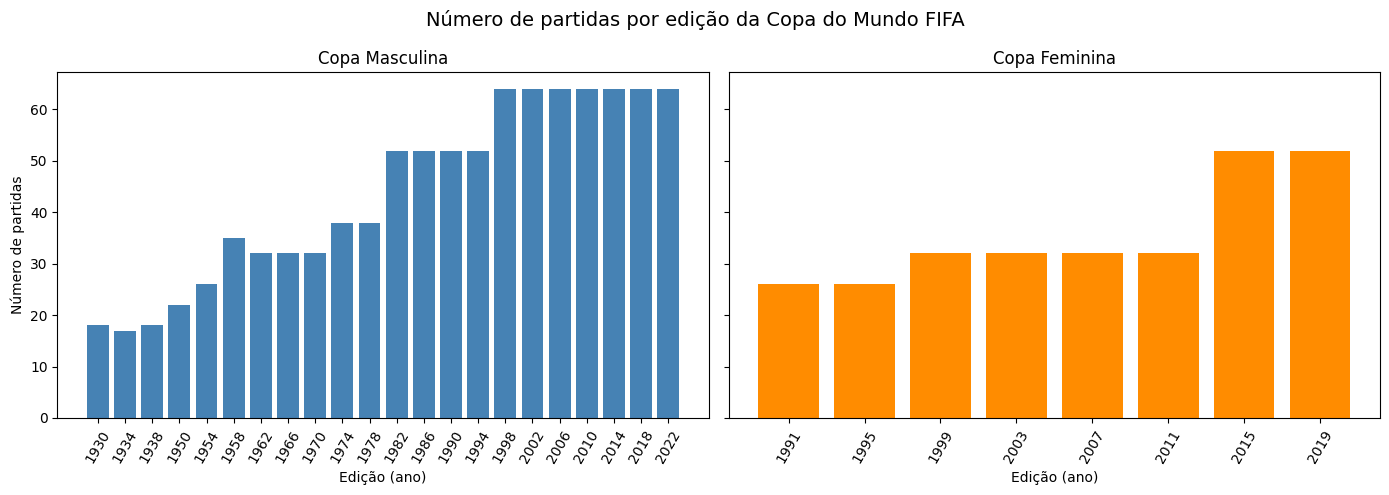

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for eixo, comp, cor in zip(eixos, ["Masculina", "Feminina"], ["steelblue", "darkorange"]):
    dados = resumo_edicao[resumo_edicao["competicao"] == comp]
    eixo.bar(dados["ano"].astype(str), dados["partidas"], color=cor)
    eixo.set_title(f"Copa {comp}")
    eixo.set_xlabel("Edição (ano)")
    eixo.tick_params(axis="x", rotation=60)

eixos[0].set_ylabel("Número de partidas")
fig.suptitle("Número de partidas por edição da Copa do Mundo FIFA", fontsize=14)
plt.tight_layout()
plt.show()

O gráfico mostra a quantidade de partidas disputadas em cada edição, separando
as competições masculina (1930–2022) e feminina (1991–2019).

Na Copa masculina, o torneio passou de 18 partidas em 1930 para 64 a partir de
1998. O crescimento ocorreu em saltos, que acompanham o aumento no número de
seleções participantes: 52 jogos a partir de 1982 e 64 a partir de 1998.

Na Copa feminina, o padrão é semelhante: 26 partidas nas duas primeiras edições,
32 a partir de 1999 e 52 a partir de 2015.

Limitação: o número de partidas reflete decisões de formato da FIFA, e não o
nível de competitividade do torneio. Os valores de 1934 e 1938 incluem partidas
de replay.

### Gráfico 2 — Média de gols por partida ao longo das edições

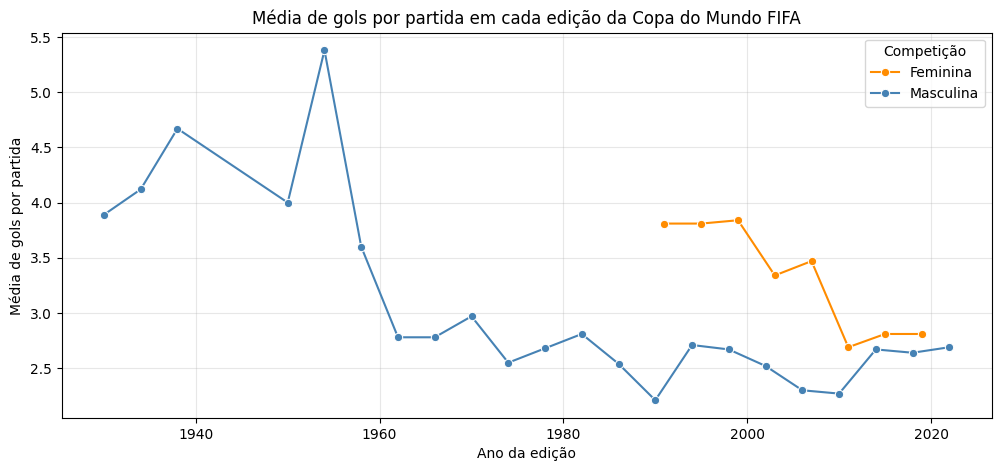

In [16]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=resumo_edicao, x="ano", y="media_gols",
             hue="competicao", marker="o",
             palette={"Masculina": "steelblue", "Feminina": "darkorange"})

plt.title("Média de gols por partida em cada edição da Copa do Mundo FIFA")
plt.xlabel("Ano da edição")
plt.ylabel("Média de gols por partida")
plt.legend(title="Competição")
plt.grid(alpha=0.3)
plt.show()

In [17]:
df.groupby("competicao")["gols_total"].agg(["mean", "median"]).round(2)

,mean,median
competicao,,
Feminina,3.23,3.0
Masculina,2.82,3.0


O gráfico mostra a média de gols por partida em cada edição.

Copa masculina: as primeiras edições tiveram médias altas, com pico de 5,38 gols
por partida em 1954. A partir dos anos 1960 a média cai para menos de 3 gols e
atinge o menor valor em 1990 (2,21). Desde 1994 se mantém estável, entre 2,2 e
2,7 gols por partida.

Copa feminina: as primeiras edições tiveram médias próximas de 3,8 gols por
partida, caindo para cerca de 2,7–2,8 a partir de 2011, valor próximo ao da Copa
masculina no mesmo período.

No conjunto, a Copa feminina tem média de 3,23 gols por partida e a masculina de
2,82.

Limitações:
- O gráfico mostra uma tendência, mas não explica sua causa. Mudanças táticas,
  de regras e de formato do torneio podem ter influenciado, mas os dados não
  permitem afirmar qual fator foi responsável.
- A Copa feminina tem apenas 8 edições, contra 22 da masculina, e começou 61 anos
  depois. A comparação direta entre as médias gerais mistura épocas diferentes.
- As goleadas identificadas na Seção 4 elevam as médias das primeiras Copas
  femininas.

## 6. Gols por fase da competição

Pergunta investigada: as partidas eliminatórias (oitavas, quartas, semifinal,
final) têm mais ou menos gols do que a fase de grupos?

Recorte: apenas a Copa masculina, que tem número suficiente de partidas em
todas as fases (a Copa feminina tem só 8 finais e 16 jogos de oitavas). Foram
consideradas as cinco fases principais; a disputa de 3º lugar e as fases que
existiram só em formatos antigos (Segunda fase de grupos e Quadrangular final)
foram deixadas de fora do gráfico.

### Gráfico 3 — Distribuição de gols por partida em cada fase

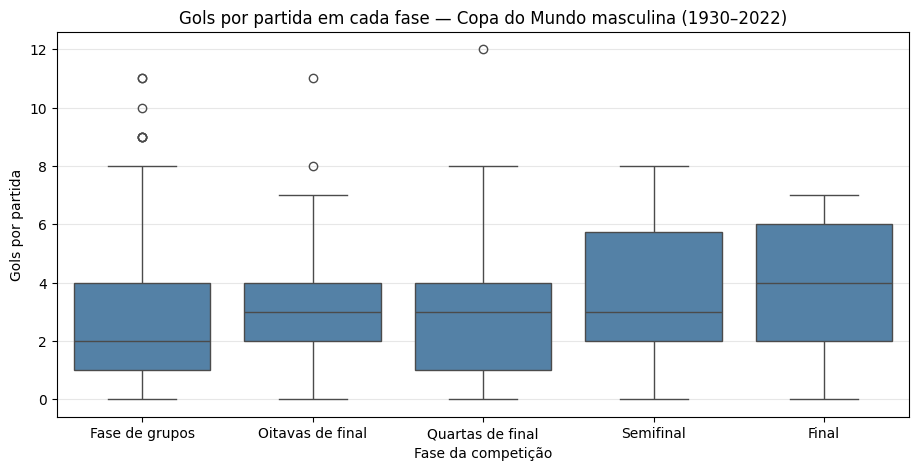

In [18]:
ordem_fases = ["Fase de grupos", "Oitavas de final", "Quartas de final",
               "Semifinal", "Final"]

masc_fases = df[(df["competicao"] == "Masculina") & (df["fase"].isin(ordem_fases))]

plt.figure(figsize=(11, 5))
sns.boxplot(data=masc_fases, x="fase", y="gols_total", order=ordem_fases,
            color="steelblue")

plt.title("Gols por partida em cada fase — Copa do Mundo masculina (1930–2022)")
plt.xlabel("Fase da competição")
plt.ylabel("Gols por partida")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [19]:
(masc_fases.groupby("fase")["gols_total"]
           .agg(partidas="count", media="mean", mediana="median")
           .round(2)
           .reindex(ordem_fases))

,partidas,media,mediana
fase,,,
Fase de grupos,676,2.67,2.0
Oitavas de final,97,3.12,3.0
Quartas de final,70,2.80,3.0
Semifinal,38,3.47,3.0
Final,21,3.81,4.0


O boxplot mostra a distribuição de gols por partida em cada fase. A linha
central de cada caixa é a mediana; a caixa concentra os 50% centrais das
partidas; os pontos isolados são placares fora do padrão.

Ao contrário do que se poderia esperar, as fases decisivas não têm menos gols.
A fase de grupos tem a menor média (2,67 gols por partida), enquanto a
semifinal (3,47) e a final (3,81) têm as maiores.

Limitações importantes:
- Partidas eliminatórias podem ter prorrogação (30 minutos a mais), o que
  aumenta a chance de gols. A comparação não é feita no mesmo tempo de jogo.
- O número de partidas é muito diferente entre as fases: 676 na fase de grupos
  contra apenas 21 finais. Com poucas partidas, a média da final é mais sensível
  a jogos isolados.
- As fases reúnem épocas diferentes. As finais das primeiras Copas, quando as
  médias de gols eram mais altas, pesam na média da fase.

## 7. Ranking de seleções por vitórias

Pergunta investigada: quais seleções mais venceram partidas em Copas do Mundo?

Recorte: apenas a Copa masculina (1930–2022).

Para contar as vitórias de cada seleção, reorganizamos os dados: cada partida
foi transformada em duas linhas, uma para cada seleção, com os gols marcados e
sofridos por ela. Assim, cada seleção é contada independentemente de ter sido
registrada como mandante ou visitante.

Seguindo a regra definida na Seção 4, partidas decididas nos pênaltis contam
como empate.

Decisão: o dataset registra "West Germany" (até 1990) e "Germany" (a partir de
1994) como seleções diferentes. Como a FIFA considera a Alemanha atual sucessora
da Alemanha Ocidental, as duas foram unificadas como "Germany".

In [20]:
masc = df[df["competicao"] == "Masculina"]

# Uma linha por seleção em cada partida
mandantes = masc[["home_team_name", "home_team_score", "away_team_score"]].copy()
mandantes.columns = ["selecao", "gols_pro", "gols_contra"]

visitantes = masc[["away_team_name", "away_team_score", "home_team_score"]].copy()
visitantes.columns = ["selecao", "gols_pro", "gols_contra"]

jogos_selecao = pd.concat([mandantes, visitantes], ignore_index=True)

# Unifica Alemanha Ocidental e Alemanha
jogos_selecao["selecao"] = jogos_selecao["selecao"].replace({"West Germany": "Germany"})

jogos_selecao["vitoria"] = (jogos_selecao["gols_pro"] > jogos_selecao["gols_contra"]).astype(int)
jogos_selecao["empate"] = (jogos_selecao["gols_pro"] == jogos_selecao["gols_contra"]).astype(int)
jogos_selecao["derrota"] = (jogos_selecao["gols_pro"] < jogos_selecao["gols_contra"]).astype(int)

print("Linhas na tabela original (masculina):", len(masc))
print("Linhas na tabela por seleção:", len(jogos_selecao))

Linhas na tabela original (masculina): 964
Linhas na tabela por seleção: 1928


A nova tabela tem o dobro de linhas da original, pois cada partida aparece uma
vez para cada seleção.

### Tabela-resumo 2 — Desempenho das seleções na Copa masculina

In [21]:
ranking = (
    jogos_selecao.groupby("selecao")
                 .agg(jogos=("vitoria", "count"),
                      vitorias=("vitoria", "sum"),
                      empates=("empate", "sum"),
                      derrotas=("derrota", "sum"),
                      gols_pro=("gols_pro", "sum"),
                      gols_contra=("gols_contra", "sum"))
)

ranking["saldo_gols"] = ranking["gols_pro"] - ranking["gols_contra"]
ranking["perc_vitorias"] = (ranking["vitorias"] / ranking["jogos"] * 100).round(1)

ranking = ranking.sort_values("vitorias", ascending=False)
ranking.head(10)

,jogos,vitorias,empates,derrotas,gols_pro,gols_contra,saldo_gols,perc_vitorias
selecao,,,,,,,,
Brazil,114,76,19,19,237,108,129,66.7
Germany,112,68,21,23,232,130,102,60.7
Argentina,88,47,17,24,152,101,51,53.4
Italy,83,45,21,17,128,77,51,54.2
France,73,39,14,20,136,85,51,53.4
England,74,32,22,20,104,68,36,43.2
Spain,67,31,17,19,108,75,33,46.3
Netherlands,55,30,14,11,96,52,44,54.5
Uruguay,59,25,13,21,89,76,13,42.4


A tabela mostra, para cada seleção, o número de partidas disputadas, vitórias,
empates, derrotas, gols marcados e sofridos, saldo de gols e o percentual de
vitórias (vitórias ÷ partidas × 100). Período: Copas masculinas de 1930 a 2022.

### Gráfico 4 — As 10 seleções com mais vitórias

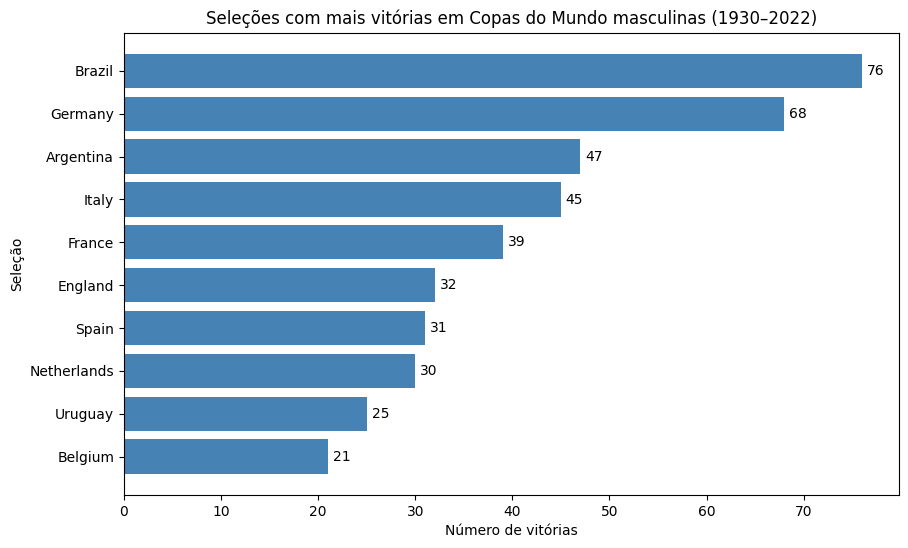

In [22]:
top10 = ranking.head(10).sort_values("vitorias")

plt.figure(figsize=(10, 6))
plt.barh(top10.index, top10["vitorias"], color="steelblue")

for i, valor in enumerate(top10["vitorias"]):
    plt.text(valor + 0.5, i, str(valor), va="center")

plt.title("Seleções com mais vitórias em Copas do Mundo masculinas (1930–2022)")
plt.xlabel("Número de vitórias")
plt.ylabel("Seleção")
plt.show()

O Brasil lidera o ranking com 76 vitórias em 114 partidas, seguido pela Alemanha
(68 vitórias em 112 partidas) e pela Argentina (47 em 88). Brasil e Alemanha se
destacam bastante das demais seleções.

O Brasil também tem o maior percentual de vitórias entre as dez primeiras
(66,7%), o que indica que a liderança não vem apenas do número de partidas
disputadas.

Limitações:
- O número de vitórias depende do número de participações. Seleções que
  disputaram mais Copas e chegaram mais longe tiveram mais oportunidades de
  vencer. O percentual de vitórias ajuda a corrigir parte desse efeito.
- A unificação das Alemanhas é uma decisão de interpretação. Sem ela, a
  Alemanha Ocidental (36 vitórias) e a Alemanha (32) apareceriam separadas e o
  ranking mudaria.
- A regra adotada para os pênaltis altera os números: uma seleção que avançou
  nos pênaltis recebe um empate, não uma vitória.

## 8. Frequência de empates

Pergunta investigada: com que frequência as partidas terminam empatadas?

Regra adotada (definida na Seção 4): é considerado empate todo jogo que terminou
com placar igual após o tempo normal e a eventual prorrogação, incluindo os
decididos nos pênaltis.

### Tabela-resumo 3 — Empates, prorrogações e pênaltis por competição

In [23]:
df["empate"] = (df["resultado"] == "Empate").astype(int)

resumo_empates = df.groupby("competicao").agg(
    partidas=("match_id", "count"),
    empates=("empate", "sum"),
    com_prorrogacao=("extra_time", "sum"),
    decididas_penaltis=("penalty_shootout", "sum")
)
resumo_empates["perc_empates"] = (resumo_empates["empates"] /
                                  resumo_empates["partidas"] * 100).round(1)

resumo_empates

,partidas,empates,com_prorrogacao,decididas_penaltis,perc_empates
competicao,,,,,
Feminina,284,39,15,8,13.7
Masculina,964,214,73,35,22.2


Na Copa masculina, 214 das 964 partidas (22,2%) terminaram empatadas. Na Copa
feminina, foram 39 de 284 (13,7%). No total, 253 partidas, das quais 43 foram
decididas nos pênaltis.

A menor frequência de empates na Copa feminina é coerente com o que foi
observado na Seção 4: as goleadas mais amplas ocorreram nessa competição, o que
sugere maior diferença de nível entre as seleções participantes.

Limitação: a frequência de empates depende do formato do torneio. Na fase de
grupos o empate é um resultado possível e às vezes conveniente; nas fases
eliminatórias, o jogo precisa ter um vencedor, o que leva à prorrogação.

## 9. Comparação: Brasil × Alemanha

Pergunta investigada: como se comparam as duas seleções com mais vitórias em
Copas do Mundo masculinas, em participações, vitórias e gols marcados?

Usamos a tabela por seleção criada na Seção 7 (com Alemanha Ocidental e Alemanha
unificadas), acrescentando o ano de cada partida.

In [24]:
# Recria a tabela por seleção incluindo o ano da partida
mand = masc[["ano", "home_team_name", "home_team_score", "away_team_score"]].copy()
mand.columns = ["ano", "selecao", "gols_pro", "gols_contra"]

visi = masc[["ano", "away_team_name", "away_team_score", "home_team_score"]].copy()
visi.columns = ["ano", "selecao", "gols_pro", "gols_contra"]

jogos_ano = pd.concat([mand, visi], ignore_index=True)
jogos_ano["selecao"] = jogos_ano["selecao"].replace({"West Germany": "Germany"})
jogos_ano["vitoria"] = (jogos_ano["gols_pro"] > jogos_ano["gols_contra"]).astype(int)

bra_ale = jogos_ano[jogos_ano["selecao"].isin(["Brazil", "Germany"])]

bra_ale.groupby("selecao").agg(
    participacoes=("ano", "nunique"),
    partidas=("vitoria", "count"),
    vitorias=("vitoria", "sum"),
    gols_marcados=("gols_pro", "sum"),
    gols_sofridos=("gols_contra", "sum")
)

,participacoes,partidas,vitorias,gols_marcados,gols_sofridos
selecao,,,,,
Brazil,22,114,76,237,108
Germany,20,112,68,232,130


O Brasil participou de todas as 22 Copas masculinas; a Alemanha, de 20 (não
disputou as edições de 1930 e 1950). Os números são muito próximos: o Brasil tem
76 vitórias e 237 gols marcados em 114 partidas; a Alemanha, 68 vitórias e 232
gols em 112 partidas. A principal diferença está nos gols sofridos: 108 do
Brasil contra 130 da Alemanha.

### Gráfico 5 — Vitórias acumuladas ao longo das edições

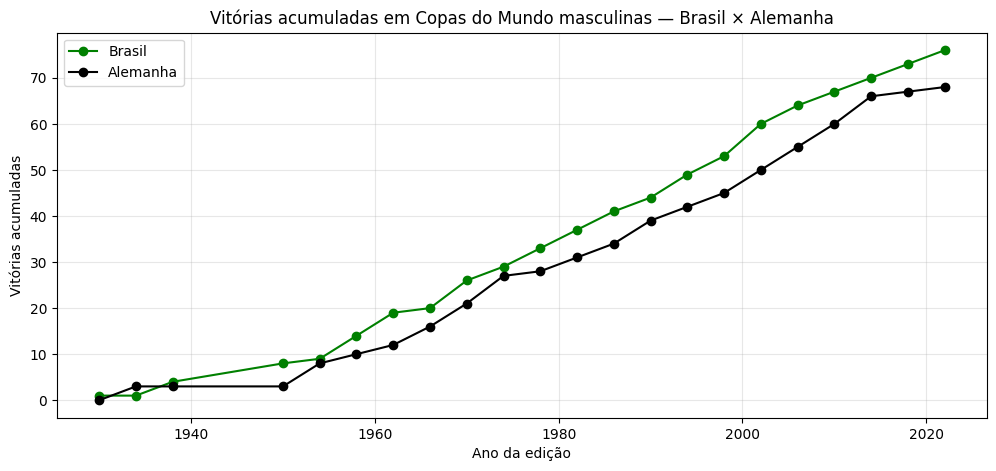

In [25]:
vitorias_ano = (bra_ale.pivot_table(index="ano", columns="selecao",
                                    values="vitoria", aggfunc="sum")
                       .fillna(0))

vitorias_acumuladas = vitorias_ano.cumsum()

plt.figure(figsize=(12, 5))
plt.plot(vitorias_acumuladas.index, vitorias_acumuladas["Brazil"],
         marker="o", color="green", label="Brasil")
plt.plot(vitorias_acumuladas.index, vitorias_acumuladas["Germany"],
         marker="o", color="black", label="Alemanha")

plt.title("Vitórias acumuladas em Copas do Mundo masculinas — Brasil × Alemanha")
plt.xlabel("Ano da edição")
plt.ylabel("Vitórias acumuladas")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [26]:
# Confrontos diretos entre as duas seleções
alemanhas = ["Germany", "West Germany"]
confrontos = masc[
    ((masc["home_team_name"] == "Brazil") & (masc["away_team_name"].isin(alemanhas))) |
    ((masc["away_team_name"] == "Brazil") & (masc["home_team_name"].isin(alemanhas)))
]
confrontos[["ano", "fase", "home_team_name", "away_team_name", "score"]]

,ano,fase,home_team_name,away_team_name,score
727,2002,Final,Germany,Brazil,0–2
1012,2014,Semifinal,Brazil,Germany,1–7


O gráfico mostra o total de vitórias de cada seleção somado edição após edição.
O Brasil está à frente desde 1938. A Alemanha reduziu a diferença ao longo do
tempo e chegou a ficar a 4 vitórias do Brasil em 2014 (70 × 66), mas as
campanhas mais curtas de 2018 e 2022 (1 vitória em cada) ampliaram novamente a
vantagem brasileira.

As duas seleções se enfrentaram apenas duas vezes em Copas: na final de 2002
(Brasil 2 × 0) e na semifinal de 2014 (Alemanha 7 × 1).

Limitações:
- A Alemanha disputou duas Copas a menos, o que reduz suas oportunidades de
  vencer.
- Com apenas dois confrontos diretos, não é possível concluir qual seleção é
  superior no duelo entre elas.
- A unificação das Alemanhas segue a decisão da Seção 7.

## 10. Conclusões

1. O torneio cresceu, mas os jogos têm menos gols. A Copa masculina passou de
   18 partidas em 1930 para 64 a partir de 1998. No mesmo período, a média de
   gols por partida caiu de valores entre 4 e 5 nas primeiras edições para uma
   faixa estável entre 2,2 e 2,7 desde 1994. Os dados mostram a tendência, mas
   não permitem identificar sua causa.

2. A Copa feminina começou com mais gols e se aproximou da masculina. As
   primeiras edições femininas tiveram média próxima de 3,8 gols por partida,
   com as maiores goleadas de todo o dataset (como 13 × 0 em 2019). A partir de
   2011 a média caiu para cerca de 2,7–2,8, próxima à da Copa masculina no mesmo
   período. A Copa feminina também tem menos empates (13,7% contra 22,2%).

3. As fases decisivas não têm menos gols. Na Copa masculina, semifinais (3,47) e
   finais (3,81) têm médias maiores que a fase de grupos (2,67). Parte dessa
   diferença pode vir da prorrogação, que só existe nas fases eliminatórias, e
   do pequeno número de finais (21).

4. Brasil e Alemanha dominam o histórico de vitórias. O Brasil lidera com 76
   vitórias e o maior percentual de vitórias entre as dez primeiras seleções
   (66,7%); a Alemanha vem logo atrás, com 68. As demais seleções estão bem
   distantes.

### Limitações gerais
- O dataset não inclui a Copa feminina de 2023.
- O formato do torneio mudou várias vezes, o que dificulta comparações diretas
  entre épocas.
- Algumas análises dependem de decisões de interpretação (pênaltis como empate,
  unificação das Alemanhas), justificadas ao longo do notebook.

## 11. Dificuldades encontradas
- Padronização dos nomes das fases, escritas de formas diferentes no dataset.
- Definição de como tratar partidas decididas nos pênaltis, já que a coluna
  original as registra como vitória.
- Reorganização dos dados para o ranking: cada partida teve de ser transformada
  em duas linhas, uma por seleção.
- Tratamento da Alemanha Ocidental e da Alemanha, registradas como seleções
  diferentes.

## Fonte dos dados
Fjelstul, Joshua C. The Fjelstul World Cup Database.
https://github.com/jfjelstul/worldcup
Arquivo: https://raw.githubusercontent.com/jfjelstul/worldcup/master/data-csv/matches.csv